In [2]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
import datasets as load_datasets

#Loading data
datasets = load_datasets.load_dataset('lukebarousse/data_jobs')
df = datasets['train'].to_pandas()

#Data cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else(x))

In [3]:
df = df[df['job_title_short'] == 'Data Analyst']

In [4]:
df_skills = df.explode('job_skills')
df_stats = df_skills.groupby('job_skills').agg(
    skill_count = ('job_skills', 'count'),
    median_salary = ('salary_year_avg', 'median')
)
df_stats = df_stats.sort_values(by='skill_count', ascending=False).head(20)
df_stats

,skill_count,median_salary
job_skills,,
sql,92428,92500.000000
excel,66860,84479.000000
python,57190,98500.000000
tableau,46455,95000.000000
power bi,39380,90000.000000
r,29996,92527.500000
sas,27998,90000.000000
powerpoint,13822,85000.000000
word,13562,80000.000000


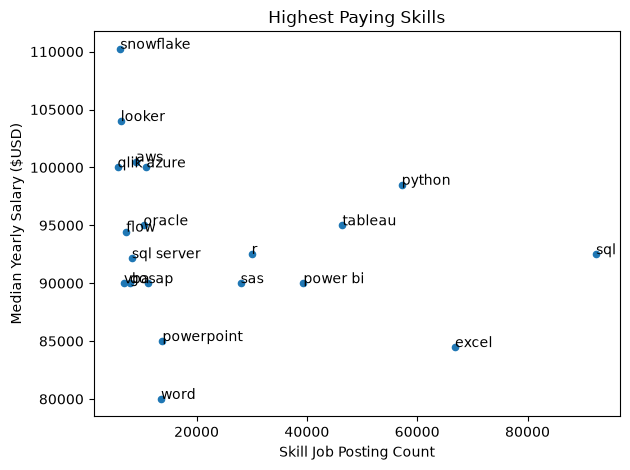

In [5]:
df_stats.plot(kind='scatter', x='skill_count', y='median_salary')
plt.title('Highest Paying Skills')
plt.xlabel('Skill Job Posting Count')
plt.ylabel('Median Yearly Salary ($USD)')

for i, txt in enumerate(df_stats.index):
    plt.text(df_stats['skill_count'].iloc[i], df_stats['median_salary'].iloc[i], txt)

plt.tight_layout()
plt.show()